# Hindi POS Tagger — Assignment 7

This notebook implements the algorithms listed in **NLP-Lab-Assignment-7-2026.pdf**:

1. **Naive Bayes classifier** using word length (`MORE`/`LESS`), current word, previous word, next word, and previous tag.
2. **Forward Viterbi** for an HMM.
3. **Backward Viterbi** for an HMM.
4. **Forward–backward decoding** for an HMM, using forward/backward probabilities and choosing the most probable tag at each token.

It evaluates each method on the development and test splits, reports precision/recall/F1 per POS tag, and plots tag-wise comparisons.

> **Terminology note:** “Forward-backward Viterbi” is not a single universally standard name. This notebook implements the standard forward–backward probability algorithm (posterior decoding) as the third HMM variant. Forward Viterbi and backward Viterbi are both max-product sequence decoding and should ordinarily return the same best sequence (apart from ties). If your instructor gave a different definition for the third variant, adapt that cell to match it.

## Expected data layout

Keep the files in a folder named `Hindi-POS-Data` beside this notebook:

```text
Assignment7/
├── Hindi-POS-Data/
│   ├── hindi-train-pos.txt
│   ├── hindi-dev-pos.txt
│   └── hindi-test-pos.txt
└── Hindi_POS_Tagging_Assignment7.ipynb
```

The parser expects one `word tag` pair per line and blank lines between sentences, as in the provided example. It uses the first and last whitespace-separated fields on each non-blank line.

In [1]:
# If any package is missing, uncomment and run this line:
# %pip install numpy pandas scikit-learn matplotlib scipy

from pathlib import Path
from collections import Counter, defaultdict
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from sklearn.feature_extraction import DictVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import precision_recall_fscore_support, classification_report, accuracy_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)


## 1. Locate and load the dataset files

If the files are stored somewhere else, update `DATA_DIR` below. The loader preserves sentence boundaries and tolerates blank lines at the end of files.

In [2]:
# Edit this path if needed. It can be a relative or absolute path.
DATA_DIR = Path("Hindi-POS-Data")
TRAIN_FILE = DATA_DIR / "hindi-train-pos.txt"
DEV_FILE   = DATA_DIR / "hindi-dev-pos.txt"
TEST_FILE  = DATA_DIR / "hindi-test-pos.txt"
OUTPUT_DIR = Path("pos_tagger_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Helpful fallback when the notebook is run from a parent directory.
if not TRAIN_FILE.exists():
    candidates = [Path("Hindi-POS-Data"), Path("Assignment7/Hindi-POS-Data"), Path(".")]
    for candidate in candidates:
        if (candidate / "hindi-train-pos.txt").exists():
            DATA_DIR = candidate
            TRAIN_FILE = DATA_DIR / "hindi-train-pos.txt"
            DEV_FILE = DATA_DIR / "hindi-dev-pos.txt"
            TEST_FILE = DATA_DIR / "hindi-test-pos.txt"
            break

def read_pos_corpus(path):
    """Read blank-line-separated POS sentences; each row is (word, tag)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path.resolve()}\n"
            "Place hindi-train-pos.txt, hindi-dev-pos.txt, and hindi-test-pos.txt "
            "inside the Hindi-POS-Data folder, or update DATA_DIR in this cell."
        )

    sentences = []
    current = []
    with path.open("r", encoding="utf-8-sig") as f:
        for raw_line in f:
            line = raw_line.strip()
            if not line:
                if current:
                    sentences.append(current)
                    current = []
                continue
            fields = line.split()
            if len(fields) < 2:
                warnings.warn(f"Skipping malformed line in {path.name}: {raw_line.rstrip()!r}")
                continue
            # Typical format is: WORD<TAB>TAG. Using first/last also tolerates extra columns.
            word, tag = fields[0], fields[-1]
            current.append((word, tag))
    if current:
        sentences.append(current)

    if not sentences:
        raise ValueError(f"No valid tagged sentences found in {path.resolve()}")
    return sentences

train_sents = read_pos_corpus(TRAIN_FILE)
dev_sents = read_pos_corpus(DEV_FILE)
test_sents = read_pos_corpus(TEST_FILE)

print(f"Data directory: {DATA_DIR.resolve()}")
print(f"Train: {len(train_sents):,} sentences, {sum(len(s) for s in train_sents):,} tokens")
print(f"Dev:   {len(dev_sents):,} sentences, {sum(len(s) for s in dev_sents):,} tokens")
print(f"Test:  {len(test_sents):,} sentences, {sum(len(s) for s in test_sents):,} tokens")
print("\nFirst sentence from training data:")
print(train_sents[0][:15])


Data directory: C:\Users\asus\OneDrive\Desktop\NLP LAB\Assignment7\Hindi-POS-Data
Train: 15,087 sentences, 325,710 tokens
Dev:   1,866 sentences, 40,762 tokens
Test:  1,910 sentences, 41,415 tokens

First sentence from training data:
[('यह', 'DM_DMD'), ('एशिया', 'N_NNP'), ('की', 'PSP'), ('सबसे', 'RP_INTF'), ('बड़ी', 'JJ'), ('मस्जिदों', 'N_NN'), ('में', 'PSP'), ('से', 'PSP'), ('एक', 'QT_QTC'), ('है', 'V_VM'), ('।', 'RD_PUNC')]


## 2. Basic data inspection / EDA

Inspect the tag distribution and sentence lengths before training. These statistics are calculated from the supplied training split.

,Statistic,Value
0,Sentences,15087.000000
1,Tokens,325710.000000
2,Unique words,18279.000000
3,Unique POS tags,24.000000
4,Mean sentence length,21.588785
5,Median sentence length,20.000000
6,Maximum sentence length,116.000000


,POS tag,Token count
5,N_NN,71442
2,PSP,64342
1,N_NNP,39578
7,V_VM,34495
10,V_VAUX,20695
8,RD_PUNC,19683
4,JJ,18281
9,PR_PRP,11543
6,QT_QTC,6456
12,CC_CCD,6319


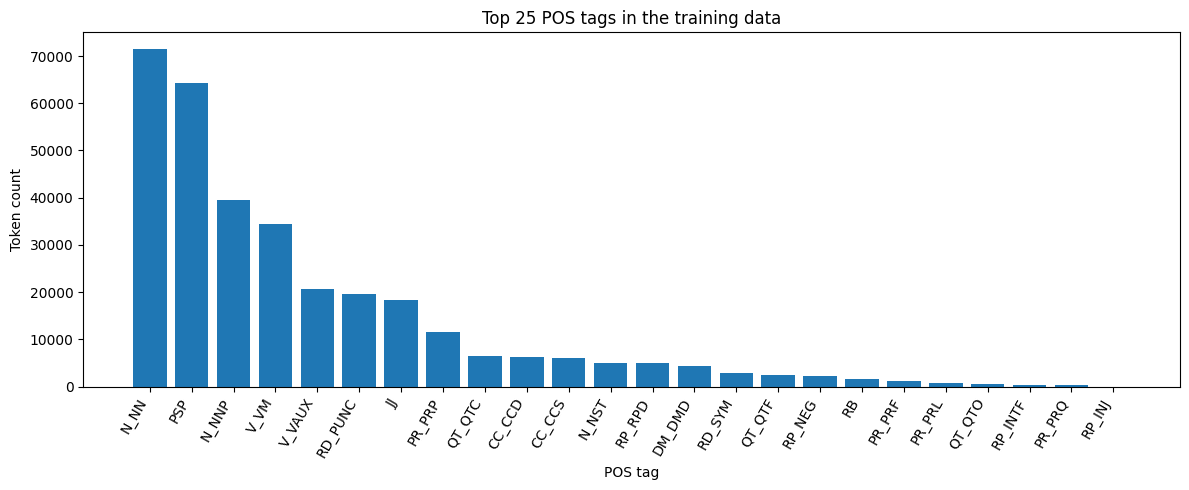

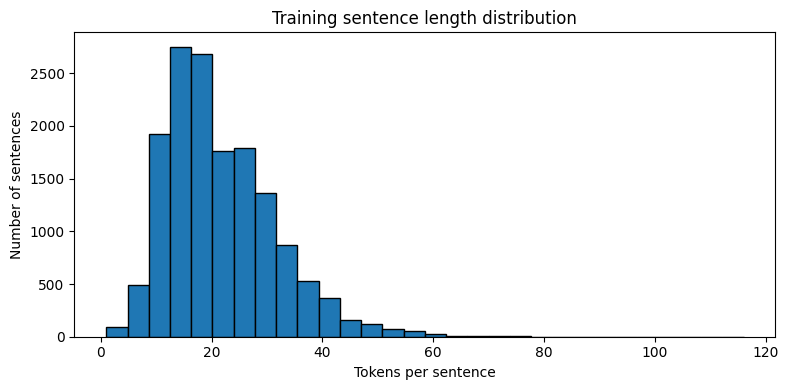

In [3]:
train_words = [word for sent in train_sents for word, _ in sent]
train_tags = [tag for sent in train_sents for _, tag in sent]
all_tags = sorted(set(train_tags))

sentence_lengths = pd.Series([len(s) for s in train_sents], name="tokens_per_sentence")
tag_counts = Counter(train_tags)
word_counts = Counter(train_words)

display(pd.DataFrame({
    "Statistic": ["Sentences", "Tokens", "Unique words", "Unique POS tags", "Mean sentence length", "Median sentence length", "Maximum sentence length"],
    "Value": [len(train_sents), len(train_words), len(word_counts), len(all_tags), sentence_lengths.mean(), sentence_lengths.median(), sentence_lengths.max()]
}))

tag_distribution = pd.DataFrame({"POS tag": list(tag_counts.keys()), "Token count": list(tag_counts.values())})
tag_distribution = tag_distribution.sort_values("Token count", ascending=False)
display(tag_distribution.head(20))

plt.figure(figsize=(12, 5))
plot_data = tag_distribution.head(25)
plt.bar(plot_data["POS tag"], plot_data["Token count"])
plt.title("Top 25 POS tags in the training data")
plt.xlabel("POS tag")
plt.ylabel("Token count")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(sentence_lengths, bins=30, edgecolor="black")
plt.title("Training sentence length distribution")
plt.xlabel("Tokens per sentence")
plt.ylabel("Number of sentences")
plt.tight_layout()
plt.show()


## 3. Algorithm 1 — Naive Bayes classifier

The classifier uses the five requested categorical features:

- `LENGTH`: `MORE` if the word length is greater than 4; otherwise `LESS`.
- `WORD`: the current word.
- `PREV_WORD`: the previous word or `<BOS>` at sentence start.
- `NEXT_WORD`: the next word or `<EOS>` at sentence end.
- `PREV_TAG`: the previous tag or `<BOS>` at sentence start.

`DictVectorizer` converts feature values into one-hot columns, and `MultinomialNB` estimates the class probabilities. During training, the previous tag is the gold tag; at prediction time, it is the **previous predicted tag** (greedy left-to-right inference), because gold previous tags are not available in real test-time prediction.

In [4]:
BOS = "<BOS>"
EOS = "<EOS>"
UNK = "<UNK>"

def sentence_words(sentence):
    return [word for word, _ in sentence]

def sentence_tags(sentence):
    return [tag for _, tag in sentence]

def make_nb_features(words, i, previous_tag):
    word = words[i]
    previous_word = words[i - 1] if i > 0 else BOS
    next_word = words[i + 1] if i + 1 < len(words) else EOS
    return {
        "LENGTH": "MORE" if len(word) > 4 else "LESS",
        "WORD": word,
        "PREV_WORD": previous_word,
        "NEXT_WORD": next_word,
        "PREV_TAG": previous_tag,
    }

def make_nb_training_examples(sentences):
    feature_rows, labels = [], []
    for sentence in sentences:
        words = sentence_words(sentence)
        tags = sentence_tags(sentence)
        for i, tag in enumerate(tags):
            previous_tag = tags[i - 1] if i > 0 else BOS
            feature_rows.append(make_nb_features(words, i, previous_tag))
            labels.append(tag)
    return feature_rows, labels

nb_vectorizer = DictVectorizer(sparse=True)
nb_classifier = MultinomialNB(alpha=0.1)
X_train_dict, y_train_nb = make_nb_training_examples(train_sents)
X_train_nb = nb_vectorizer.fit_transform(X_train_dict)
nb_classifier.fit(X_train_nb, y_train_nb)


def predict_naive_bayes(sentence):
    """Greedy sequential decoding; the previous feature is the previous predicted tag."""
    words = sentence_words(sentence)
    predicted_tags = []
    for i in range(len(words)):
        previous_tag = predicted_tags[i - 1] if i > 0 else BOS
        features = make_nb_features(words, i, previous_tag)
        x = nb_vectorizer.transform([features])
        predicted_tags.append(nb_classifier.predict(x)[0])
    return predicted_tags

print("Naive Bayes fitted.")
print("Number of training tokens:", len(y_train_nb))
print("Number of one-hot feature columns:", len(nb_vectorizer.feature_names_))


Naive Bayes fitted.
Number of training tokens: 325710
Number of one-hot feature columns: 54604


## 4. Algorithms 2–4 — HMM variants

The HMM estimates start, transition, and emission probabilities from training sentences only. Additive smoothing prevents zero probabilities. Rare training words are mapped to `<UNK>` for emissions, and unseen development/test words are also mapped to `<UNK>`. All decoding is performed in log space for numerical stability.

In [5]:
class HMMTagger:
    def __init__(self, alpha=0.1, rare_cutoff=1):
        self.alpha = float(alpha)
        self.rare_cutoff = int(rare_cutoff)
        self.tags = []
        self.tag_to_idx = {}
        self.vocab = set()
        self.log_start = None
        self.log_end = None
        self.log_transition = None
        self.log_emission = None

    def _map_word(self, word):
        return word if word in self.vocab else UNK

    def fit(self, sentences):
        tag_counts = Counter()
        word_counts = Counter()
        for sentence in sentences:
            for word, tag in sentence:
                tag_counts[tag] += 1
                word_counts[word] += 1

        self.tags = sorted(tag_counts.keys())
        self.tag_to_idx = {tag: i for i, tag in enumerate(self.tags)}
        self.vocab = {word for word, count in word_counts.items() if count > self.rare_cutoff}
        self.vocab.add(UNK)

        n_tags = len(self.tags)
        vocab_list = sorted(self.vocab)
        word_to_idx = {word: i for i, word in enumerate(vocab_list)}

        start_counts = Counter()
        end_counts = Counter()
        transition_counts = np.zeros((n_tags, n_tags), dtype=np.float64)
        emission_counts = np.zeros((n_tags, len(vocab_list)), dtype=np.float64)
        tag_out_counts = np.zeros(n_tags, dtype=np.float64)
        tag_emission_totals = np.zeros(n_tags, dtype=np.float64)

        for sentence in sentences:
            if not sentence:
                continue
            mapped_tags = [tag for _, tag in sentence]
            mapped_words = [self._map_training_word(word, word_counts) for word, _ in sentence]
            start_counts[mapped_tags[0]] += 1
            end_counts[mapped_tags[-1]] += 1
            for word, tag in zip(mapped_words, mapped_tags):
                ti = self.tag_to_idx[tag]
                wi = word_to_idx[word]
                emission_counts[ti, wi] += 1
                tag_emission_totals[ti] += 1
            for left_tag, right_tag in zip(mapped_tags[:-1], mapped_tags[1:]):
                li, ri = self.tag_to_idx[left_tag], self.tag_to_idx[right_tag]
                transition_counts[li, ri] += 1
                tag_out_counts[li] += 1
            tag_out_counts[self.tag_to_idx[mapped_tags[-1]]] += 1  # final tag -> END

        a = self.alpha
        start_array = np.array([start_counts[t] for t in self.tags], dtype=np.float64)
        end_array = np.array([end_counts[t] for t in self.tags], dtype=np.float64)
        self.log_start = np.log((start_array + a) / (len(sentences) + a * n_tags))
        # Transition matrix has n_tags regular next states plus one END state.
        self.log_transition = np.log((transition_counts + a) / (tag_out_counts[:, None] + a * (n_tags + 1)))
        self.log_end = np.log((end_array + a) / (tag_out_counts + a * (n_tags + 1)))
        self.log_emission = np.log((emission_counts + a) / (tag_emission_totals[:, None] + a * len(vocab_list)))
        self.word_to_idx = word_to_idx
        return self

    def _map_training_word(self, word, word_counts):
        return word if word_counts[word] > self.rare_cutoff else UNK

    def _emission_scores(self, words):
        """Return an array [token position, tag]."""
        mapped = [self._map_word(w) for w in words]
        out = np.empty((len(words), len(self.tags)), dtype=np.float64)
        for i, word in enumerate(mapped):
            wi = self.word_to_idx[word]
            out[i, :] = self.log_emission[:, wi]
        return out

    def predict_forward_viterbi(self, sentence):
        words = sentence_words(sentence)
        if not words:
            return []
        n, k = len(words), len(self.tags)
        emissions = self._emission_scores(words)
        delta = np.full((n, k), -np.inf)
        backpointer = np.zeros((n, k), dtype=np.int32)
        delta[0] = self.log_start + emissions[0]
        for i in range(1, n):
            scores = delta[i - 1][:, None] + self.log_transition
            backpointer[i] = np.argmax(scores, axis=0)
            delta[i] = np.max(scores, axis=0) + emissions[i]
        last_tag = int(np.argmax(delta[-1] + self.log_end))
        path = [last_tag]
        for i in range(n - 1, 0, -1):
            path.append(int(backpointer[i, path[-1]]))
        path.reverse()
        return [self.tags[j] for j in path]

    def predict_backward_viterbi(self, sentence):
        """Backward max-product dynamic programming, then left-to-right path reconstruction."""
        words = sentence_words(sentence)
        if not words:
            return []
        n, k = len(words), len(self.tags)
        emissions = self._emission_scores(words)
        best_suffix = np.full((n, k), -np.inf)
        next_pointer = np.zeros((n, k), dtype=np.int32)
        best_suffix[-1] = self.log_end
        for i in range(n - 2, -1, -1):
            # score for current tag -> next tag -> observed next word -> best suffix
            scores = self.log_transition + emissions[i + 1][None, :] + best_suffix[i + 1][None, :]
            next_pointer[i] = np.argmax(scores, axis=1)
            best_suffix[i] = np.max(scores, axis=1)
        first_scores = self.log_start + emissions[0] + best_suffix[0]
        current = int(np.argmax(first_scores))
        path = [current]
        for i in range(n - 1):
            current = int(next_pointer[i, current])
            path.append(current)
        return [self.tags[j] for j in path]

    def predict_forward_backward(self, sentence):
        """Forward-backward sum-product; choose the maximum posterior tag per token."""
        words = sentence_words(sentence)
        if not words:
            return []
        n, k = len(words), len(self.tags)
        emissions = self._emission_scores(words)

        log_alpha = np.full((n, k), -np.inf)
        log_beta = np.full((n, k), -np.inf)
        log_alpha[0] = self.log_start + emissions[0]
        for i in range(1, n):
            log_alpha[i] = emissions[i] + logsumexp(
                log_alpha[i - 1][:, None] + self.log_transition, axis=0
            )

        log_beta[-1] = self.log_end
        for i in range(n - 2, -1, -1):
            log_beta[i] = logsumexp(
                self.log_transition + emissions[i + 1][None, :] + log_beta[i + 1][None, :],
                axis=1,
            )

        log_likelihood = logsumexp(log_alpha[-1] + self.log_end)
        log_posterior = log_alpha + log_beta - log_likelihood
        best_tags = np.argmax(log_posterior, axis=1)
        return [self.tags[j] for j in best_tags]

hmm = HMMTagger(alpha=0.1, rare_cutoff=1).fit(train_sents)
print(f"HMM fitted: {len(hmm.tags)} tags, {len(hmm.vocab):,} emission vocabulary items")


HMM fitted: 24 tags, 10,564 emission vocabulary items


## 5. Evaluate on development and test sets

The metric table includes each tag from the training set. Tags never predicted receive an F1 score of zero. For a fair comparison, all methods are evaluated against the same gold tags and label set.

In [6]:
MODEL_PREDICTORS = {
    "Naive Bayes": predict_naive_bayes,
    "Forward Viterbi": hmm.predict_forward_viterbi,
    "Backward Viterbi": hmm.predict_backward_viterbi,
    "Forward-Backward": hmm.predict_forward_backward,
}

def evaluate_model(model_name, predictor, sentences, split_name, labels):
    y_true, y_pred = [], []
    for sentence in sentences:
        gold = sentence_tags(sentence)
        predicted = predictor(sentence)
        if len(gold) != len(predicted):
            raise ValueError(f"{model_name} predicted {len(predicted)} tags for {len(gold)} tokens.")
        y_true.extend(gold)
        y_pred.extend(predicted)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )
    per_tag = pd.DataFrame({
        "split": split_name,
        "model": model_name,
        "tag": labels,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
    })
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0
    )
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="weighted", zero_division=0
    )
    summary = {
        "split": split_name,
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_p,
        "weighted_recall": weighted_r,
        "weighted_f1": weighted_f1,
        "tokens": len(y_true),
    }
    return per_tag, summary, y_true, y_pred

labels = sorted(set(train_tags))
per_tag_frames = []
summary_rows = []
all_predictions = {}

for split_name, sentences in [("dev", dev_sents), ("test", test_sents)]:
    print(f"Evaluating on {split_name}...")
    for model_name, predictor in MODEL_PREDICTORS.items():
        per_tag, summary, y_true, y_pred = evaluate_model(model_name, predictor, sentences, split_name, labels)
        per_tag_frames.append(per_tag)
        summary_rows.append(summary)
        all_predictions[(split_name, model_name)] = (y_true, y_pred)

per_tag_results = pd.concat(per_tag_frames, ignore_index=True)
summary_results = pd.DataFrame(summary_rows)

summary_display = summary_results.copy()
metric_cols = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_precision", "weighted_recall", "weighted_f1"]
summary_display[metric_cols] = summary_display[metric_cols].round(4)
display(summary_display.sort_values(["split", "macro_f1"], ascending=[True, False]))


Evaluating on dev...
Evaluating on test...


,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,tokens
3,dev,Forward-Backward,0.9357,0.9380,0.9357,0.9363,0.9360,0.9357,0.9358,40762
1,dev,Forward Viterbi,0.9352,0.9351,0.9362,0.9352,0.9356,0.9352,0.9353,40762
2,dev,Backward Viterbi,0.9352,0.9351,0.9362,0.9352,0.9356,0.9352,0.9353,40762
0,dev,Naive Bayes,0.9314,0.8848,0.8379,0.8528,0.9314,0.9314,0.9310,40762
5,test,Forward Viterbi,0.9347,0.9054,0.8978,0.9004,0.9356,0.9347,0.9349,41415
6,test,Backward Viterbi,0.9347,0.9054,0.8978,0.9004,0.9356,0.9347,0.9349,41415
7,test,Forward-Backward,0.9351,0.9072,0.8921,0.8985,0.9358,0.9351,0.9353,41415
4,test,Naive Bayes,0.9319,0.8895,0.8410,0.8562,0.9322,0.9319,0.9316,41415


## 6. Detailed per-tag F1 tables

These tables answer the requirement to report F1 for every tag on both dev and test data.

In [7]:
for split_name in ["dev", "test"]:
    print(f"Per-tag F1 — {split_name}")
    table = per_tag_results[per_tag_results["split"] == split_name].pivot(index="tag", columns="model", values="f1")
    table = table.reindex(columns=list(MODEL_PREDICTORS.keys()))
    display(table.round(4))


Per-tag F1 — dev


model,Naive Bayes,Forward Viterbi,Backward Viterbi,Forward-Backward
tag,,,,
CC_CCD,0.9597,0.9779,0.9779,0.9773
CC_CCS,0.9666,0.9753,0.9753,0.9784
DM_DMD,0.9030,0.9556,0.9556,0.9542
JJ,0.8764,0.8712,0.8712,0.8744
N_NN,0.9087,0.9089,0.9089,0.9093
N_NNP,0.8490,0.8466,0.8466,0.8428
N_NST,0.9334,0.9808,0.9808,0.9823
PR_PRF,0.9639,0.9967,0.9967,0.9967
PR_PRL,0.8696,0.9384,0.9384,0.9429


Per-tag F1 — test


model,Naive Bayes,Forward Viterbi,Backward Viterbi,Forward-Backward
tag,,,,
CC_CCD,0.9745,0.9775,0.9775,0.9770
CC_CCS,0.9662,0.9767,0.9767,0.9800
DM_DMD,0.9189,0.9560,0.9560,0.9529
JJ,0.8967,0.8786,0.8786,0.8811
N_NN,0.9034,0.9033,0.9033,0.9033
N_NNP,0.8475,0.8499,0.8499,0.8498
N_NST,0.9283,0.9784,0.9784,0.9792
PR_PRF,0.9530,0.9967,0.9967,0.9967
PR_PRL,0.8671,0.9101,0.9101,0.9149


## 7. Plots: overall comparison and per-tag F1

To keep the labels readable when a corpus has many tags, the per-tag comparison is split into pages of up to 25 tags. Each plot compares all four methods for the same tags.

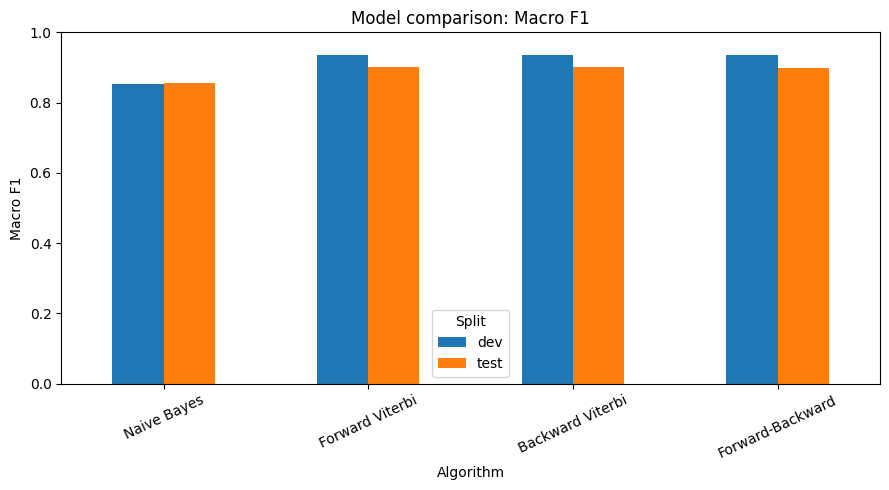

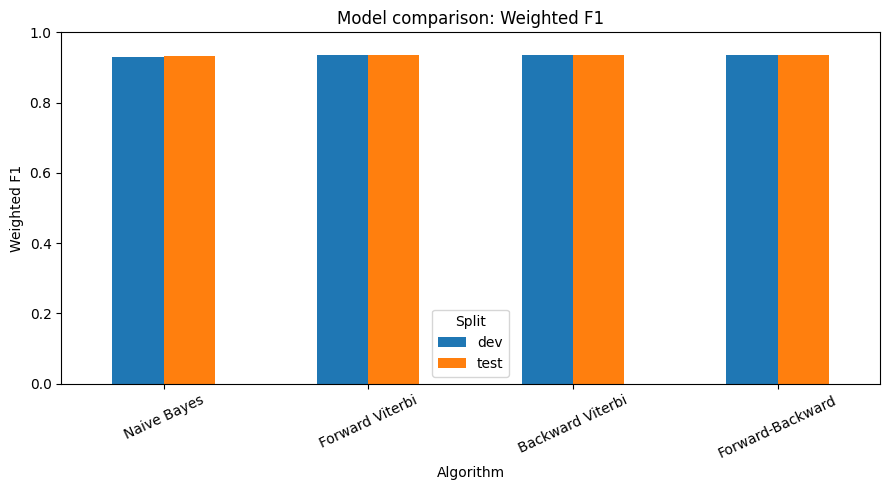

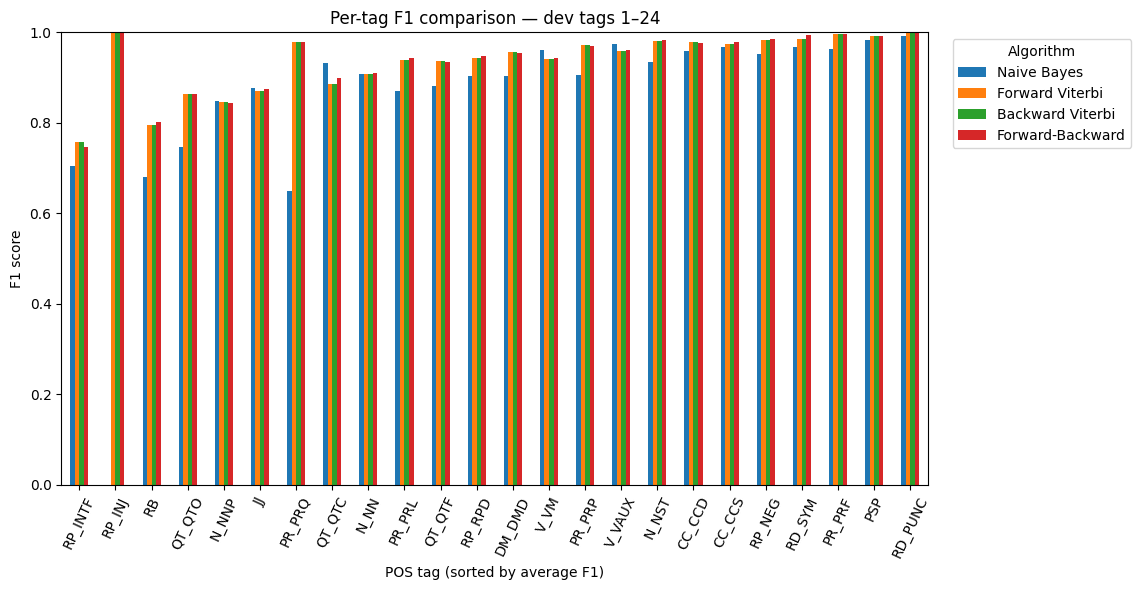

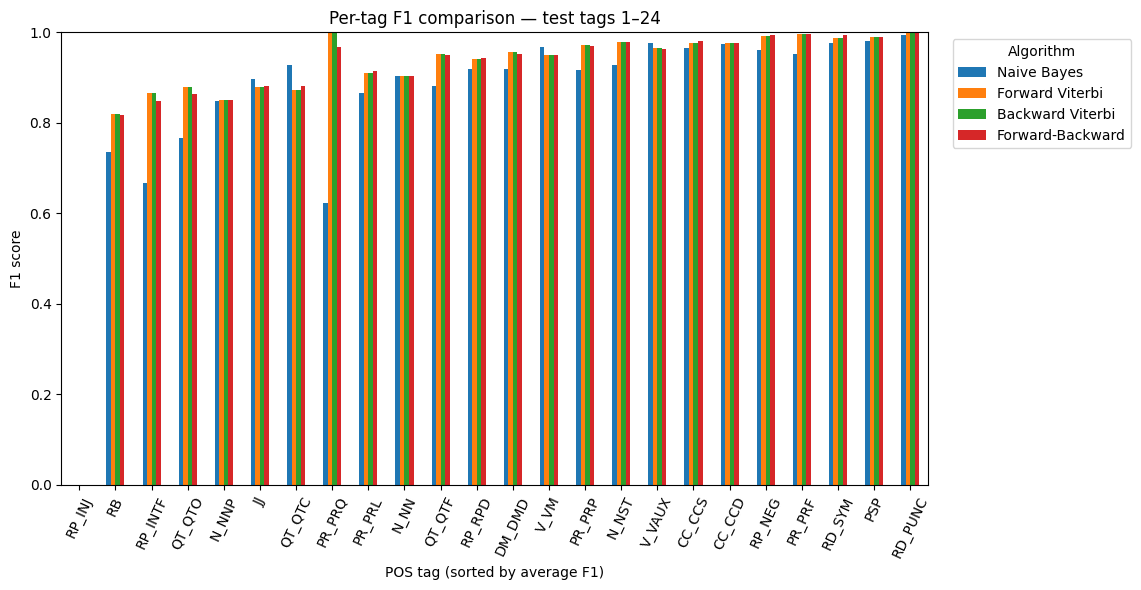

In [8]:
# Overall macro-F1 and weighted-F1 comparison
for metric in ["macro_f1", "weighted_f1"]:
    pivot = summary_results.pivot(index="model", columns="split", values=metric)
    pivot = pivot.reindex(index=list(MODEL_PREDICTORS.keys()))
    ax = pivot.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"Model comparison: {metric.replace('_', ' ').title()}")
    ax.set_xlabel("Algorithm")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)
    ax.legend(title="Split")
    plt.tight_layout()
    plt.show()

# Per-tag F1 plots for dev and test
models_in_order = list(MODEL_PREDICTORS.keys())
for split_name in ["dev", "test"]:
    f1_table = per_tag_results[per_tag_results["split"] == split_name].pivot(index="tag", columns="model", values="f1")
    f1_table = f1_table.reindex(columns=models_in_order)
    # Order tags by average F1 across models to make differences easier to inspect.
    f1_table = f1_table.loc[f1_table.mean(axis=1).sort_values(ascending=True).index]
    chunk_size = 25
    for start in range(0, len(f1_table), chunk_size):
        chunk = f1_table.iloc[start:start + chunk_size]
        ax = chunk.plot(kind="bar", figsize=(max(11, len(chunk) * 0.48), 6))
        ax.set_title(f"Per-tag F1 comparison — {split_name} tags {start + 1}–{start + len(chunk)}")
        ax.set_xlabel("POS tag (sorted by average F1)")
        ax.set_ylabel("F1 score")
        ax.set_ylim(0, 1)
        ax.tick_params(axis="x", rotation=65)
        ax.legend(title="Algorithm", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.show()


## 8. Save results to CSV

The notebook writes metric tables into `pos_tagger_outputs/` so that they can be included in your assignment report.

In [9]:
summary_path = OUTPUT_DIR / "summary_metrics.csv"
per_tag_path = OUTPUT_DIR / "per_tag_metrics.csv"
summary_results.to_csv(summary_path, index=False, encoding="utf-8-sig")
per_tag_results.to_csv(per_tag_path, index=False, encoding="utf-8-sig")

print("Saved:")
print(" -", summary_path.resolve())
print(" -", per_tag_path.resolve())


Saved:
 - C:\Users\asus\OneDrive\Desktop\NLP LAB\Assignment7\pos_tagger_outputs\summary_metrics.csv
 - C:\Users\asus\OneDrive\Desktop\NLP LAB\Assignment7\pos_tagger_outputs\per_tag_metrics.csv


## 9. Notes for your report

- The Naive Bayes model is trained using the previous **gold** tag as a feature but uses the previous **predicted** tag at inference time. This makes prediction possible for unseen sentences, though it can cause error propagation.
- Forward Viterbi and backward Viterbi optimize the same whole-sequence HMM objective, so their output and scores should usually agree. Differences can occur with ties or implementation mistakes; if they differ substantially, inspect the decoding code.
- Forward–backward posterior decoding chooses the most likely tag at each position independently. This can differ from Viterbi's single most likely **whole sequence**.
- The HMM uses additive smoothing (`alpha=0.1`) and maps singleton training words to `<UNK>`. For an experiment, you can vary `alpha` and `rare_cutoff`, retrain the HMM, and rerun evaluation. Keep the test set for final reporting rather than tuning on it.
- Include the summary table, per-tag F1 tables, and plots in your lab report. State the selected smoothing settings and any preprocessing decisions.

### Sanity check

Before submitting, verify that all three files were loaded, that each model returns exactly one tag per input token, and that the output folder contains both CSV files. The assignment's supplied data files are required to obtain the real scores; no sample metrics are fabricated here.